# 🚀 Indian Startup Funding Analysis (2015–2017)

**An Exploratory Data Analysis (EDA) project on startup funding deals in India**

---

## 📌 Project Overview
Between 2015 and 2017, thousands of Indian startups raised funding across multiple sectors, cities, and investor groups. This project explores a dataset of **2,372 funding records** to understand *where the money went, who gave it, and how the ecosystem evolved over time*.

The goal isn't just to run `groupby()` repeatedly — it's to walk through a realistic data-analyst workflow: clean messy real-world data, ask sharp business questions, answer them with code, and pull out insights that would matter to a founder, investor, or journalist covering the Indian startup scene.

## 🎯 Objectives
- Clean and standardize a messy, inconsistently formatted funding dataset
- Answer 25+ specific business questions using univariate and grouped analysis
- Profile individual investors and startups in depth (case studies: **IDG Ventures**, **Lenskart**)
- Identify funding trends over time, across cities, sectors, and investment rounds
- Summarize everything into a final set of data-backed insights and open questions

## 🗂️ Dataset
| | |
|---|---|
| **Source** | `startup_funding.csv` — Indian startup funding records |
| **Rows** | 2,372 raw → 2,181 after cleaning |
| **Time period** | 2015 – 2017 |
| **Key columns** | Date, Startup Name, Industry Vertical, Sub-Vertical, City, Investor(s), Investment Type (round), Amount (USD → converted to ₹ Crore) |

## 🛠️ Tools & Libraries
`pandas` · `numpy` · `matplotlib` · `seaborn`

## 🧭 Notebook Structure
1. **Data Cleaning** — handling nulls, renaming columns, currency conversion, date parsing
2. **Exploratory Data Analysis** — 25 guided business questions on startups, cities, sectors, rounds, investors
3. **Investor-Column Analysis** — equal-split funding attribution per investor
4. **Single Investor Deep Dive** — case study on IDG Ventures
5. **Overall Analysis** — total capital deployed, funding trends over time
6. **Specific Startup Deep Dive** — case study on Lenskart
7. **Key Insights & Conclusions** — summary of findings + open questions for further research

---


In [ ]:
# importing Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv("startup_funding.csv")

In [ ]:
df.shape

(2372, 10)

In [ ]:
df.head()

,SNo,Date,StartupName,IndustryVertical,SubVertical,CityLocation,InvestorsName,InvestmentType,AmountInUSD,Remarks
0,0,01/08/2017,TouchKin,Technology,Predictive Care Platform,Bangalore,Kae Capital,Private Equity,"1,300,000",NaN
1,1,02/08/2017,Ethinos,Technology,Digital Marketing Agency,Mumbai,Triton Investment Advisors,Private Equity,NaN,NaN
2,2,02/08/2017,Leverage Edu,Consumer Internet,Online platform for Higher Education Services,New Delhi,"Kashyap Deorah, Anand Sankeshwar, Deepak Jain,...",Seed Funding,NaN,NaN
3,3,02/08/2017,Zepo,Consumer Internet,DIY Ecommerce platform,Mumbai,"Kunal Shah, LetsVenture, Anupam Mittal, Hetal ...",Seed Funding,"500,000",NaN
4,4,02/08/2017,Click2Clinic,Consumer Internet,healthcare service aggregator,Hyderabad,"Narottam Thudi, Shireesh Palle",Seed Funding,"850,000",NaN


In [ ]:
df['InvestmentType'] = df['InvestmentType'].astype("category")

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2372 entries, 0 to 2371
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   SNo               2372 non-null   int64   
 1   Date              2372 non-null   object  
 2   StartupName       2372 non-null   object  
 3   IndustryVertical  2201 non-null   object  
 4   SubVertical       1436 non-null   object  
 5   CityLocation      2193 non-null   object  
 6   InvestorsName     2364 non-null   object  
 7   InvestmentType    2371 non-null   category
 8   AmountInUSD       1525 non-null   object  
 9   Remarks           419 non-null    object  
dtypes: category(1), int64(1), object(8)
memory usage: 169.6+ KB


### 🔍 First Look
The raw dataset has **2,372 rows and 10 columns**, mixing dates, text, and a messy `AmountInUSD` field stored as a string with commas. Several columns — especially `Remarks`, `SubVertical`, and `AmountInUSD` — have significant missing data, which is addressed in the cleaning steps below.

# Data Cleaning

### Preprocessing Steps

- **Remarks column** – mostly null values, so it's dropped
- **Index** – set to `SNo`
- **Column names** – renamed to simpler, consistent names
- **Amount** – converted from USD to INR Crore
- **Date column** – parsed into proper datetime format
- **Missing values** – dropped rows with nulls (`dropna`)

In [ ]:
#1 drop Remarks Col
df=df.drop(columns=["Remarks"],axis=1)



#2  Index =SNo
df.set_index('SNo',inplace=True)

#3 rename COlumns
df.rename(columns={"StartupName":"startup",
                   "IndustryVertical":'vertical',
                   'SubVertical':'subvertical',
                   'CityLocation':"city",
                   'InvestorsName':'investor',
                   'InvestmentType':'round',
                   'AmountInUSD':"amount"
                   },inplace=True)
#4 convert amount to crore
# first there are so many Nan values change them to 0
df['amount']=df['amount'].fillna('0')
print(df['amount'].isnull().sum())

# now change the type of the amount
df['amount']=df['amount'].str.replace(",",'')

# Convert the column to numeric (may be float and int)
df['amount']=pd.to_numeric(df['amount'])
df.head(4)


0


,Date,startup,vertical,subvertical,city,investor,round,amount
SNo,,,,,,,,
0,01/08/2017,TouchKin,Technology,Predictive Care Platform,Bangalore,Kae Capital,Private Equity,1300000
1,02/08/2017,Ethinos,Technology,Digital Marketing Agency,Mumbai,Triton Investment Advisors,Private Equity,0
2,02/08/2017,Leverage Edu,Consumer Internet,Online platform for Higher Education Services,New Delhi,"Kashyap Deorah, Anand Sankeshwar, Deepak Jain,...",Seed Funding,0
3,02/08/2017,Zepo,Consumer Internet,DIY Ecommerce platform,Mumbai,"Kunal Shah, LetsVenture, Anupam Mittal, Hetal ...",Seed Funding,500000


In [ ]:
# converting the amount to crore
def ConverterToCr(dollar):
    inr=dollar * 82.5
    return inr/10000000

df['amount']=df['amount'].apply(ConverterToCr)


In [ ]:
df['amount'].iloc[0:3]

,amount
SNo,
0,10.725
1,0.000
2,0.000


In [ ]:
# 5 date to datetime obj
df['Date'] = pd.to_datetime(df['Date'], format='%d/%m/%Y', errors='coerce', dayfirst=True)

__It helps to get the day ,month, year from the date__

In [ ]:
df['Date'].dt.month.head()

,Date
SNo,
0,8.0
1,8.0
2,8.0
3,8.0
4,8.0


In [ ]:
df['Date'].dt.year.head()

,Date
SNo,
0,2017.0
1,2017.0
2,2017.0
3,2017.0
4,2017.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2372 entries, 0 to 2371
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Date         2367 non-null   datetime64[ns]
 1   startup      2372 non-null   object        
 2   vertical     2201 non-null   object        
 3   subvertical  1436 non-null   object        
 4   city         2193 non-null   object        
 5   investor     2364 non-null   object        
 6   round        2371 non-null   category      
 7   amount       2372 non-null   float64       
dtypes: category(1), datetime64[ns](1), float64(1), object(5)
memory usage: 150.9+ KB


In [ ]:
# 6 drop the missing value rows
df=df.dropna(subset=['Date','vertical','city','investor','round','amount'])

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2181 entries, 0 to 2200
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Date         2181 non-null   datetime64[ns]
 1   startup      2181 non-null   object        
 2   vertical     2181 non-null   object        
 3   subvertical  1428 non-null   object        
 4   city         2181 non-null   object        
 5   investor     2181 non-null   object        
 6   round        2181 non-null   category      
 7   amount       2181 non-null   float64       
dtypes: category(1), datetime64[ns](1), float64(1), object(5)
memory usage: 138.8+ KB


### ✅ Cleaning Recap

- **`Remarks` column** – dropped (mostly empty)
- **Column names** – renamed to short, consistent names (`startup`, `vertical`, `city`, `investor`, `round`, `amount`)
- **Amount** – converted from a comma-formatted USD string → numeric → **₹ Crore**
- **Date** – parsed into a proper `datetime` object (unparseable dates dropped)
- **Remaining nulls** – rows still missing `Date`, `vertical`, `city`, `investor`, `round`, or `amount` were dropped

**Result:** the dataset shrank from **2,372 → 2,181 rows** (a ~7.6% drop), mostly due to missing amount/date/vertical data.

# Exploratory Data Analysis

__1. How many startups are there in total?__

In [ ]:
Unique_Startups=df['startup'].unique()
print(Unique_Startups)
df['startup'].nunique()

['TouchKin' 'Ethinos' 'Leverage Edu' ... 'Dazo' 'Tradelab' 'PiQube']


1863

**💡 Insight (Q1):** The cleaned dataset contains **1,863 unique startups** across **2,181 funding records** — meaning several hundred records represent *repeat* funding rounds for the same startup, not first-time raises.

__2. Analyze Distribution of Funding Amount__

In [ ]:
df['amount'].describe()

,amount
count,2181.000000
mean,64.563352
std,442.650269
min,0.000000
25%,0.000000
50%,2.475000
75%,18.975000
max,11550.000000


(0.0, 300.0)

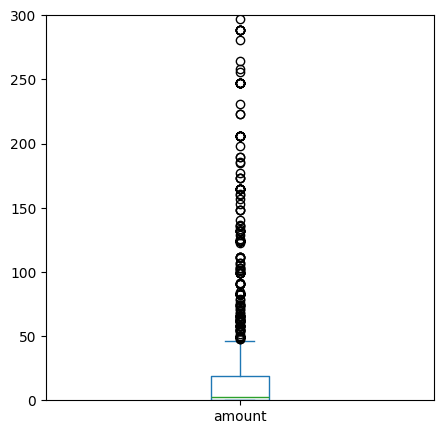

In [ ]:

plt.figure(figsize=(5,5))
df['amount'].plot(kind='box')
plt.ylim(0, 300)

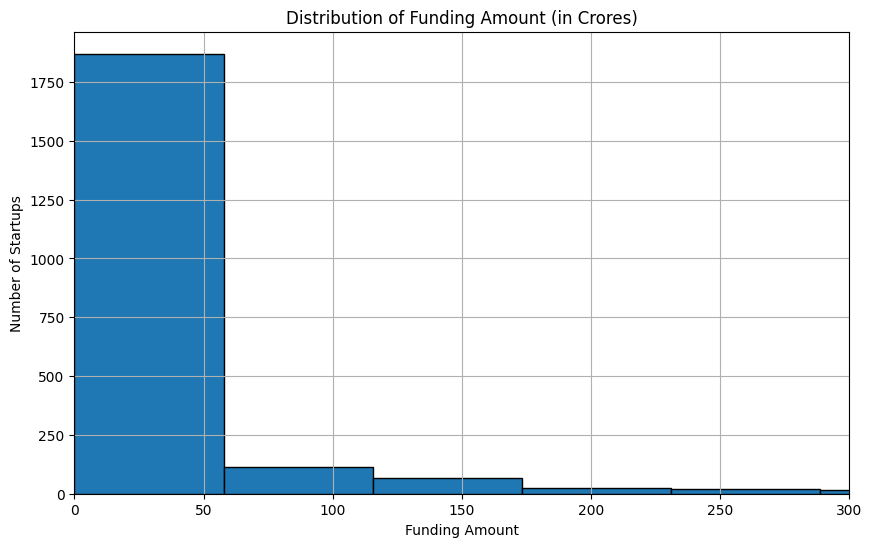

In [ ]:
plt.figure(figsize=(10,6))
df['amount'].plot(kind='hist', bins=200, edgecolor='black')
plt.title("Distribution of Funding Amount (in Crores)")
plt.xlim(0, 300)
plt.xlabel("Funding Amount")
plt.ylabel("Number of Startups")
plt.grid(True)
plt.show()


**💡 Insight (Q2) — Funding is heavily right-skewed:** the median deal is only **₹2.47 Cr**, while the mean is **₹64.6 Cr** — pulled up by mega-deals as large as **₹11,550 Cr**. 75% of deals are under ₹19 Cr. Most startups raised under ₹50 Cr (1,800+ of them); very few crossed ₹100–200 Cr. This is the classic venture-funding power law: a handful of large, late-stage rounds account for a disproportionate share of total capital.

In [ ]:
"""Most startups got low funding:
The first bar (0-50 Cr) is very tall — this means most startups received less than ₹50 Cr in funding.
Over 1800 startups fall into this bin — that’s the vast majority.


Few startups got large funding:
The bars after ₹50 Cr get very short.
Very few startups received funding over ₹100 Cr, and even fewer over ₹200 Cr.
"""

'Most startups got low funding:\nThe first bar (0-50 Cr) is very tall — this means most startups received less than ₹50 Cr in funding.\nOver 1800 startups fall into this bin — that’s the vast majority.\n\n\nFew startups got large funding:\nThe bars after ₹50 Cr get very short.\nVery few startups received funding over ₹100 Cr, and even fewer over ₹200 Cr.\n'

__3. Top 10 Cities with Most Startups__

In [ ]:
df.groupby("city")['startup'].nunique()

,startup
city,
Agra,2
Ahmedabad,32
Bangalore,523
Bangalore / Palo Alto,1
Bangalore / SFO,2
...,...
Udaipur,1
Udupi,2
Vadodara,8


In [ ]:
df.groupby("city")['startup'].nunique().sort_values(ascending=False).reset_index()

,city,startup
0,Bangalore,523
1,Mumbai,387
2,New Delhi,339
3,Gurgaon,199
4,Pune,78
...,...,...
65,USA,1
66,Udaipur,1
67,USA/India,1
68,Varanasi,1


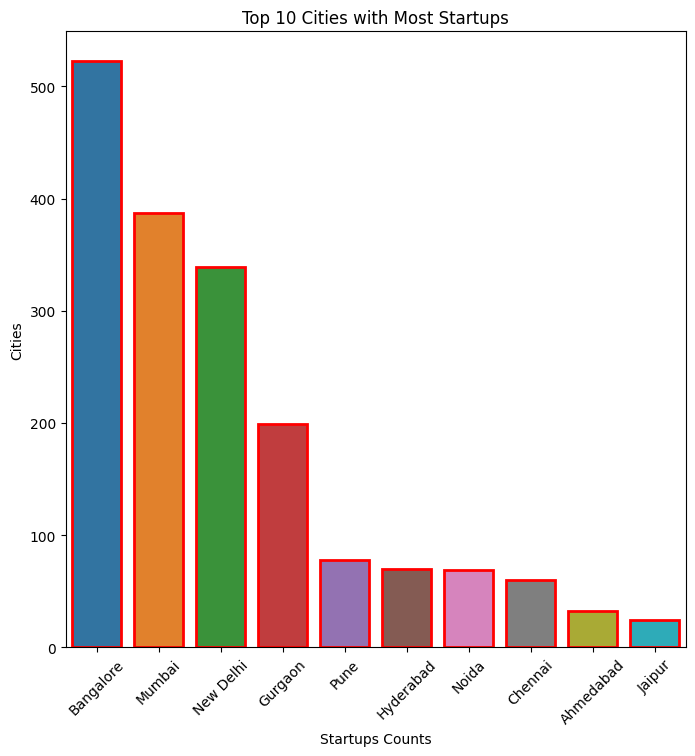

In [ ]:
fig=plt.subplots(figsize=(8,8))
top_10_Startup_per_city=df.groupby("city")['startup'].nunique().sort_values(ascending=False).head(10).reset_index()
ax=sns.barplot(data=top_10_Startup_per_city,x='city',y='startup',hue='city',linewidth=2,edgecolor='red')
plt.title("Top 10 Cities with Most Startups")
plt.xlabel("Startups Counts")
plt.ylabel("Cities")
plt.xticks(rotation=45)
plt.show()

**💡 Insight (Q3):** Funding is geographically concentrated — **Bangalore (523 startups)**, **Mumbai (387)**, and **New Delhi (339)** together account for well over half of all funded startups, while tier-2 cities barely register. The ecosystem was still heavily metro-centric in 2015–2017.

*(Data-quality note: city names have inconsistent casing/spelling — e.g. `"bangalore"` vs `"Bangalore"` — a good target for further cleanup.)*

__4. Top 10 sectors (vertical) receiving the most funding.__

In [ ]:
df['vertical'].value_counts()

,count
vertical,
Consumer Internet,765
Technology,313
eCommerce,171
ECommerce,53
Healthcare,30
...,...
Home Made Food Marketplace,1
residential rental management platform,1
Personalized Stock Intelligence Platform,1


In [ ]:
df.groupby("vertical")['amount'].sum().sort_values(ascending=False)

,amount
vertical,
Consumer Internet,31325.551125
eCommerce,20152.374000
ECommerce,15133.780266
Technology,9104.646375
Online Marketplace,5775.000000
...,...
anonymous bulletin board app,0.000000
Algorithmic Match Making Platform,0.000000
solar products and services marketplace,0.000000


In [ ]:
# ECommerce and eCommerce are same but differnt Rows (Change manually )
vertical=df.groupby("vertical")['amount'].sum()
vertical.loc['ECommerce']+=vertical.loc['eCommerce']
vertical.loc['eCommerce']=0
top_10_vertical=vertical.sort_values(ascending=False).head(10).reset_index()
top_10_vertical

,vertical,amount
0,ECommerce,35286.154266
1,Consumer Internet,31325.551125
2,Technology,9104.646375
3,Online Marketplace,5775.000000
4,E-Commerce & M-Commerce platform,5610.000000
5,Car Aggregator & Retail Mobile App,4125.000000
6,Ecommerce Marketplace,4125.000000
7,Cab Aggregator,3300.000000
8,Cab rental Mobile app,1856.250000
9,Logistics,1490.321250


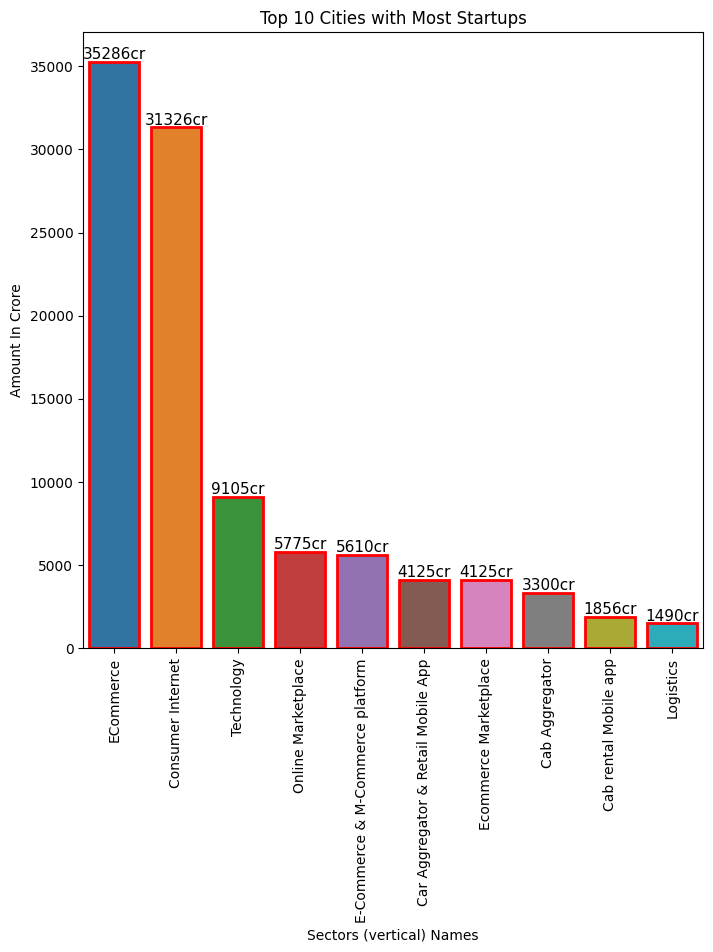

In [ ]:
fig=plt.subplots(figsize=(8,8))
ax=sns.barplot(data=top_10_vertical,x='vertical',y='amount',hue='vertical',linewidth=2,edgecolor='red')
plt.title("Top 10 Cities with Most Startups")
plt.xlabel("Sectors (vertical) Names")
plt.ylabel("Amount In Crore")
plt.xticks(rotation=90)
for i in ax.patches:
    height=i.get_height()
    ax.text(
        i.get_x()+i.get_width()/2,
        height,
        f'{height:.0f}cr',
        va='bottom',ha='center',
        fontsize=11
    )
plt.show()

**💡 Insight (Q4):** After merging the duplicate `ECommerce`/`eCommerce` labels, **E-Commerce (₹35,286 Cr)** and **Consumer Internet (₹31,326 Cr)** together absorbed the vast majority of total capital, far ahead of Technology (₹9,105 Cr) — reflecting the e-commerce and internet-first consumer growth story of that era.

__5. Most common funding rounds.__

In [ ]:
df['round'].value_counts()
# Seed Funding

,count
round,
Seed Funding,1201
Private Equity,979
Debt Funding,1
Crowd funding,0
Crowd Funding,0
PrivateEquity,0
SeedFunding,0


**💡 Insight (Q5):** **Seed Funding (1,201 deals)** is nearly as common as **Private Equity (979 deals)**, with **Debt Funding** appearing just once. A roughly 55/45 seed-to-growth split suggests a healthy early-stage pipeline alongside a surprisingly active later-stage/PE market.

__6. Top 10 Frequent Investor__

In [ ]:
df['investor'].str.split(",").explode().str.strip().value_counts().reset_index()

,investor,count
0,Sequoia Capital,54
1,Accel Partners,51
2,Indian Angel Network,40
3,Kalaari Capital,39
4,,38
...,...,...
2403,Nexus venture Partners,1
2404,GFC,1
2405,Version One Ventures,1
2406,Nexus Venture Partners and Arena Ventures,1


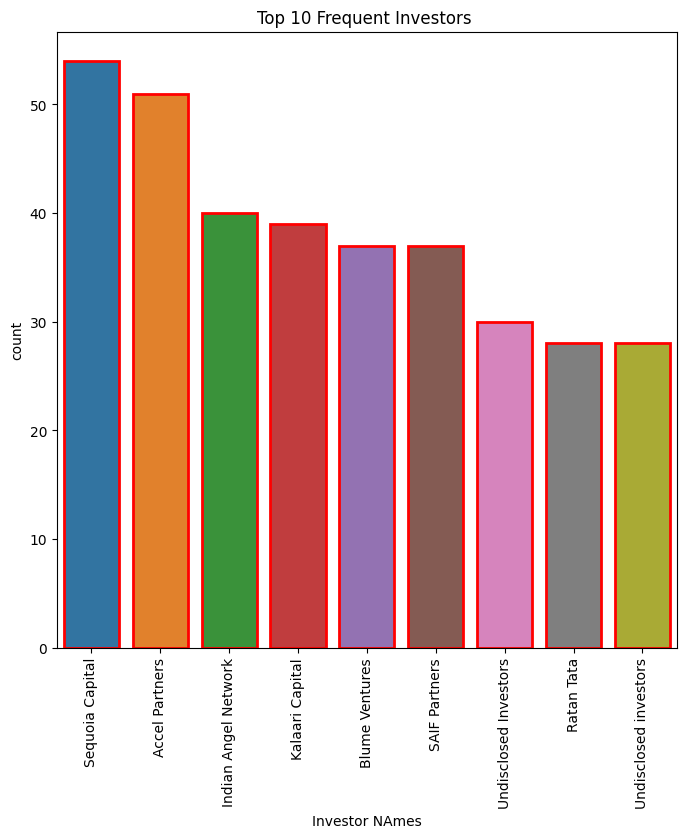

In [ ]:
investors=df['investor'].str.split(",").explode().str.strip().value_counts().reset_index().head(10)
cleaned_investors=investors[investors['investor']!='']
fig=plt.subplots(figsize=(8,8))
ax=sns.barplot(data=cleaned_investors,x='investor',y='count',hue='investor',linewidth=2,edgecolor='red')
plt.title("Top 10 Frequent Investors ")
plt.xlabel("Investor NAmes")
plt.xticks(rotation=90)
plt.show()

**💡 Insight (Q6):** **Sequoia Capital (54 deals)**, **Accel Partners (51)**, and **Indian Angel Network (40)** are the most *active* investors by raw deal count — this counts appearances, not unique startups or capital deployed (explored separately in the Investor-Column Analysis section).

__7. Count of startups funded each year/month.__

In [ ]:
# first creating the Year and Date columns
df['Year']=df['Date'].dt.year
df['month']=df['Date'].dt.month

In [ ]:
# getting overview of year and month wise startups counts
df.groupby(['Year','month'])['startup'].count()

Year  month
2015  4         61
      5         55
      6         84
      7         97
      8         98
      9         87
      10        93
      11        90
      12        88
2016  1        104
      2         99
      3         84
      4         77
      5         79
      6         97
      7         63
      8         87
      9         73
      10        80
      11        72
      12        72
2017  1         72
      2         48
      3         71
      4         71
      5         67
      6         65
      7         42
      8          5
Name: startup, dtype: int64

In [ ]:
# only year wise startup counts
df.groupby(['Year'])['startup'].count()

,startup
Year,
2015,753
2016,987
2017,441


In [ ]:
# converting above month and year wise count Multi-index series to Dataframe
monthly_counts = df.groupby(['Year', 'month'])['startup'].count().reset_index(name='Startup Counts')
monthly_counts

,Year,month,Startup Counts
0,2015,4,61
1,2015,5,55
2,2015,6,84
3,2015,7,97
4,2015,8,98
5,2015,9,87
6,2015,10,93
7,2015,11,90
8,2015,12,88
9,2016,1,104


In [ ]:
monthly_counts['Yearmonth']=pd.to_datetime(monthly_counts[['Year','month']].assign(DAY=1))

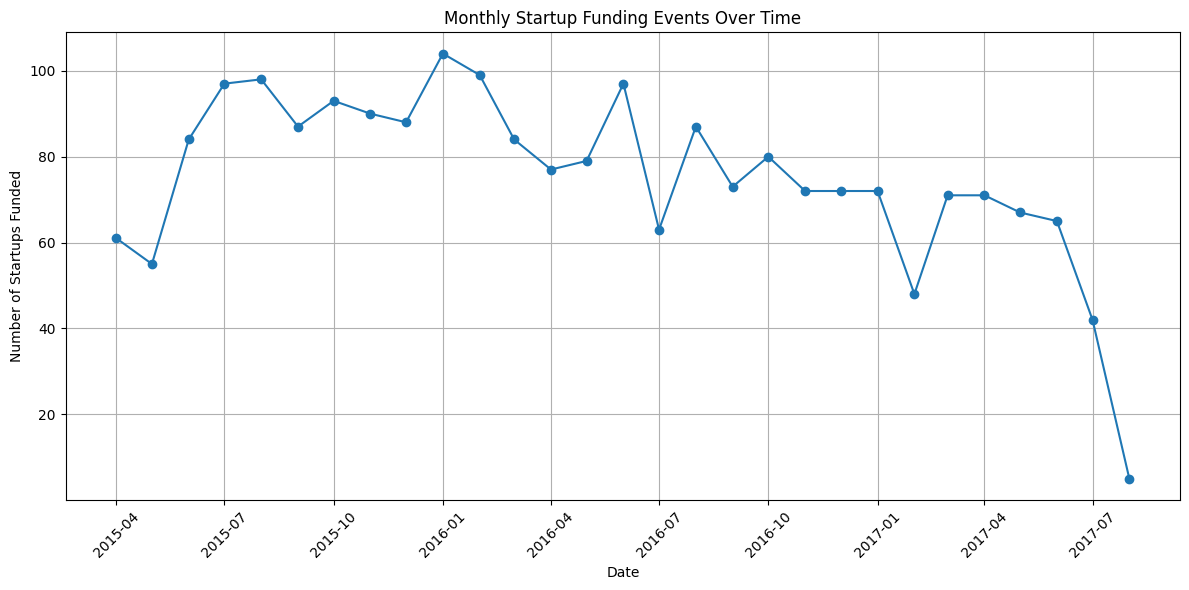

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(monthly_counts['Yearmonth'], monthly_counts['Startup Counts'], marker='o')
plt.title('Monthly Startup Funding Events Over Time')
plt.xlabel('Date')
plt.ylabel('Number of Startups Funded')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

**💡 Insight (Q7) — Funding activity peaked in 2016:** events rose from 753 (2015) → **987 in 2016** → 441 in 2017 (partial-year data). The monthly trend line is fairly steady without one dominant seasonal spike, meaning deal flow stayed active across most of the year.

__8. Number of Unique Investors__

In [ ]:
df['investor'].str.split(",").explode().str.strip().str.lower().nunique()

2365

**💡 Insight (Q8):** After cleaning for case and whitespace, there are **2,365 unique individual investors** — a large, fragmented base rather than a small closed circle of firms.

__9.Number of unique startups.__

In [ ]:
# similarly as we do in above
len(set(df['startup'].str.split(",").sum()))

1863

In [ ]:
# usnig nunique()for direct answer
df['startup'].nunique()

1863

**💡 Insight (Q9):** Confirms **1,863 unique startups**, consistent with the Q1 count and validating the cleaning approach.

__10. Top 10 sub-verticals funded most often.__

In [ ]:
df['subvertical'].value_counts()

,count
subvertical,
Food Delivery Platform,8
Online Pharmacy,8
Online lending platform,5
Online Learning Platform,4
Online Payment Gateway,3
...,...
Online Vegetable eTailer,1
Babycare Products seller,1
online to offline marketing platform,1


In [ ]:
df.groupby('subvertical')['amount'].sum().sort_values(ascending=False)

,amount
subvertical,
ECommerce Marketplace,14025.0
Mobile Wallet & ECommerce platform,12045.0
App based cab aggregator,2722.5
Cab Aggregator App,2145.0
Branded Budget Hotels Aggregator,2062.5
...,...
Healthcare Analytics Platform,0.0
Health-based social networking & discovery App,0.0
Health Technology platform,0.0


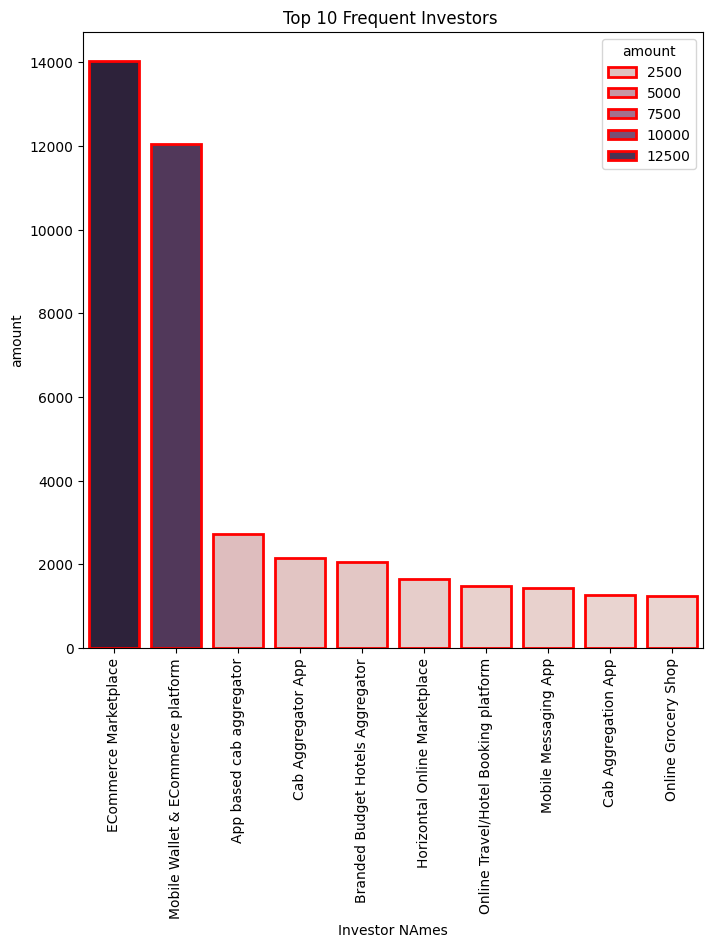

In [ ]:
subvertical_top10=df.groupby('subvertical')['amount'].sum().sort_values(ascending=False).head(10).reset_index()
fig=plt.subplots(figsize=(8,8))
ax=sns.barplot(data=subvertical_top10,x='subvertical',y='amount',hue='amount',linewidth=2,edgecolor='red')
plt.title("Top 10 Frequent Investors ")
plt.xlabel("Investor NAmes")
plt.xticks(rotation=90)
plt.show()

**💡 Insight (Q10):** The top sub-verticals by total capital are **E-Commerce Marketplace (₹14,025 Cr)** and **Mobile Wallet & E-Commerce platform (₹12,045 Cr)** — both heavily skewed by a few mega-rounds (see Q11).

__11. Highest single funding amount.__

In [ ]:
df[df['amount']==df['amount'].max()]

,Date,startup,vertical,subvertical,city,investor,round,amount,Year,month
SNo,,,,,,,,,,
158,2017-05-18,Paytm,ECommerce,Mobile Wallet & ECommerce platform,Bangalore,SoftBank Group,Private Equity,11550.0,2017,5
294,2017-03-21,Flipkart,eCommerce,ECommerce Marketplace,Bangalore,"Microsoft, eBay, Tencent Holdings",Private Equity,11550.0,2017,3


**💡 Insight (Q11) — The single largest deals:** **Paytm** and **Flipkart** each pulled in rounds worth several thousand crore — these mega-deals are the main reason the overall funding distribution is so right-skewed (see Q2).

__12. Lowest (non-zero) funding amount.__

In [ ]:
non_zero_funding=df[df['amount']!=0]
non_zero_funding[non_zero_funding['amount']==non_zero_funding['amount'].min()]

,Date,startup,vertical,subvertical,city,investor,round,amount,Year,month
SNo,,,,,,,,,,
439,2017-01-30,Maptags,Consumer Internet,Smart Online address tags,Bangalore,The Ten Minute Million,Seed Funding,0.1485,2017,1


**💡 Insight (Q12):** The smallest non-zero funding round belongs to **Maptags** — a reminder that alongside mega-deals, plenty of micro/seed cheques (well under ₹1 Cr) also show up in the data.

__13. Number of startups with zero/unknown funding.__

In [ ]:
zero_funding=df[df['amount']==0]
zero_funding.shape[0]

798

**💡 Insight (Q13):** **798 records** have `amount == 0`, meaning the funding amount was undisclosed for roughly **37% of all cleaned records**. Any "total funding" figure computed from this data is therefore a *floor*, not the true total.

__14. Which cities receive the highest average funding per startup?__



In [ ]:
highest_avg_per_startup=df.groupby('city')[['startup','amount']].agg({'startup':'count','amount':['mean','sum']})

In [ ]:
highest_avg_per_startup=highest_avg_per_startup.sort_values(by=('amount','sum'),ascending=False)
highest_avg_per_startup.style.background_gradient(cmap='Greys')


**💡 Insight (Q14):** Beyond raw deal *count*, **Bangalore also leads in total and average funding amount per startup** — reinforcing its position as India's primary startup hub, not just its most active one.

__15. Most common funding round per city.__

In [ ]:
## Group by both 'city' and 'round' and then count the number of occurrences# Group by both 'city' and 'round' and then count the number of occurrences
city_roundgroup=df.groupby(['city','round']).size().sort_values(ascending=False)

/tmp/ipykernel_1267/1039727793.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  city_roundgroup=df.groupby(['city','round']).size().sort_values(ascending=False)


In [ ]:
# To make the output more readable, you can unstack the 'round' level
# This will create a table-like format with cities as rows and rounds as columns
city_round_table = city_roundgroup.unstack(fill_value=0)
city_round_table

round,Crowd Funding,Crowd funding,Debt Funding,Private Equity,PrivateEquity,Seed Funding,SeedFunding
city,,,,,,,
Agra,0,0,0,0,0,2,0
Ahmedabad,0,0,1,11,0,23,0
Bangalore,0,0,0,304,0,322,0
Bangalore / Palo Alto,0,0,0,0,0,1,0
Bangalore / SFO,0,0,0,1,0,1,0
...,...,...,...,...,...,...,...
Udaipur,0,0,0,1,0,0,0
Udupi,0,0,0,1,0,1,0
Vadodara,0,0,0,2,0,7,0


**💡 Insight (Q15):** **Seed Funding dominates in every major city**, but the *share* of Private Equity deals is noticeably higher in Bangalore and Mumbai than in smaller hubs — consistent with those cities also hosting more later-stage, scaled-up companies.

__16. Most common funding round per sector(vertical).__

In [ ]:
df.groupby(['vertical','round']).size().sort_values(ascending=False)

/tmp/ipykernel_1267/827090479.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(['vertical','round']).size().sort_values(ascending=False)


vertical                           round         
Consumer Internet                  Seed Funding      466
                                   Private Equity    298
Technology                         Seed Funding      163
                                   Private Equity    150
eCommerce                          Private Equity     91
                                                    ... 
Home rental platform               Crowd Funding       0
Home Stay & room rentals platform  SeedFunding         0
                                   PrivateEquity       0
                                   Private Equity      0
Home services marketplace          Crowd Funding       0
Length: 5138, dtype: int64

**💡 Insight (Q16):** **Seed Funding is the most common round within every top sector** (e.g. Consumer Internet: 466 seed vs 298 PE deals) — sectors attract early believers well before growth-stage capital follows.

__17. Year with the highest number of funding events.__

In [ ]:
df.groupby("Year")['startup'].count()

,startup
Year,
2015,753
2016,987
2017,441


In [ ]:
df['Year'].value_counts() # max 2016

,count
Year,
2016,987
2015,753
2017,441


**💡 Insight (Q17):** **2016 was the peak year** for funding events (987), ahead of 2015 (753) and 2017 (441, partial year) — consistent with 2016 being a high point for Indian VC activity before a broader funding slowdown.

__18. Month with most startup fundings overall.__

In [ ]:
df['month'].value_counts() # Mostly funding in June (6)

,count
month,
6,246
4,209
7,202
5,201
8,190
1,176
10,173
11,162
12,160


**💡 Insight (Q18):** **June is the busiest month** for funding announcements (246 deals), followed by April and July. There's no dramatic seasonality — deal announcements spread fairly evenly across the year with a slight mid-year cluster.

__19. Which sectors(vertical) have the highest average funding?__

In [ ]:
avg_funding_per_sector = df.groupby('vertical')['amount'].mean().sort_values(ascending=False).head(10)

In [ ]:
avg_funding_per_sector

,amount
vertical,
Online Marketplace,5775.000
E-Commerce & M-Commerce platform,5610.000
Ecommerce Marketplace,4125.000
Car Aggregator & Retail Mobile App,4125.000
Cab Aggregator,3300.000
Online Classifieds,1237.500
Logistics Solution Provider,1130.250
Hyper-local Grocery Delivery platform,990.000
Cab rental Mobile app,928.125


**💡 Insight (Q19):** Niche categories like **Online Marketplace (₹5,775 Cr avg)** and **E-Commerce & M-Commerce platforms (₹5,610 Cr avg)** post the *highest average* deal size — skewed upward by a small number of massive single rounds rather than broad-based large funding across the sector.

__20.How often are Private Equity vs Seed Funding used ?(round)__

In [ ]:
df['round'].value_counts()

,count
round,
Seed Funding,1201
Private Equity,979
Debt Funding,1
Crowd funding,0
Crowd Funding,0
PrivateEquity,0
SeedFunding,0


<Axes: ylabel='count'>

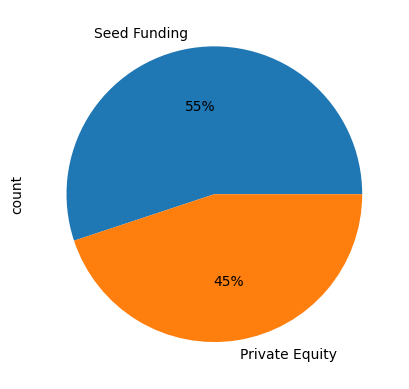

In [ ]:
df['round'].value_counts().head(2).plot(kind='pie', autopct='%1.0f%%')

**💡 Insight (Q20):** **Seed Funding (1,201) is more common than Private Equity (979)** in raw deal count, but PE/growth rounds carry far more capital per deal — "many small bets, few big bets," a familiar venture-funding pattern.

__21. Top 10 startups by total funding received.__

In [ ]:
df["startupcleaned"]=df['startup'].str.strip().str.lower()
df['startupcleaned'].value_counts()

,count
startupcleaned,
swiggy,7
urbanclap,6
jugnoo,5
byju’s,5
medinfi,5
...,...
daily ninja,1
tokri,1
repaireasy,1


In [ ]:
startup_top10=df.groupby('startupcleaned')['amount'].sum().sort_values(ascending=False).head(10).reset_index(name='Total')
startup_top10

,startupcleaned,Total
0,paytm,17655.000
1,flipkart,12867.525
2,ola,8122.125
3,flipkart.com,5775.000
4,snapdeal,5775.000
5,ola cabs,4248.750
6,olacabs,3300.000
7,oyo rooms,2887.500
8,quikr,1897.500
9,delhivery,1773.750


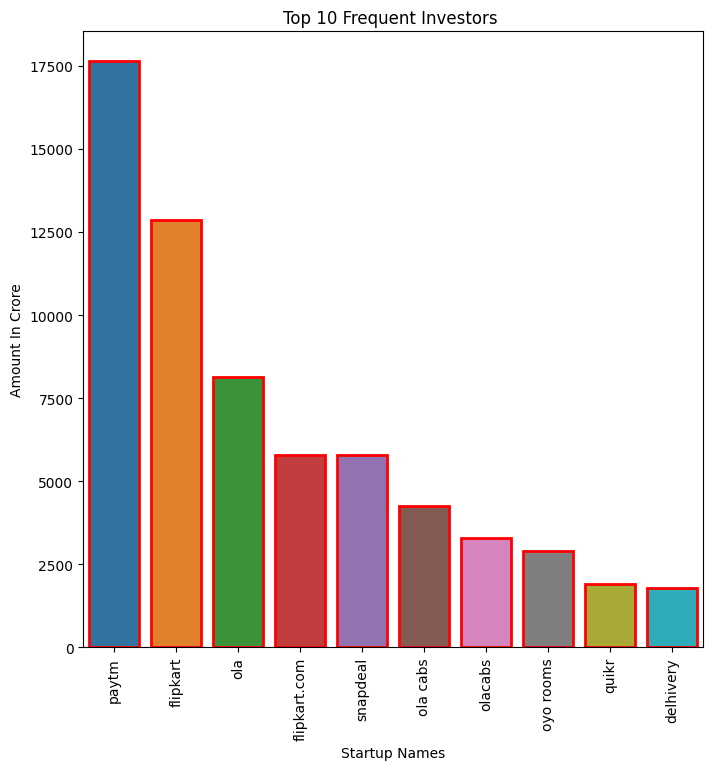

In [ ]:
fig=plt.subplots(figsize=(8,8))
ax=sns.barplot(data=startup_top10,x='startupcleaned',y='Total',hue='startupcleaned',linewidth=2,edgecolor='red')
plt.title("Top 10 Frequent Investors ")
plt.xlabel("Startup Names")
plt.ylabel("Amount In Crore")
plt.xticks(rotation=90)
plt.show()

**💡 Insight (Q21) — Who captured the most capital:** **Paytm (₹17,655 Cr)**, **Flipkart (₹12,867 Cr)**, and **Ola (₹8,122 Cr)** top the list by total funding. Note that entries like `Flipkart` / `Flipkart.Com` and `Ola` / `Ola Cabs` / `Olacabs` are the *same* company recorded inconsistently — a real data-quality issue worth flagging rather than silently merging away.

__22. Top 10 investors by number of startups invested in.__

In [ ]:
df['cleaned_investor']=df['investor'].str.split(",")
df['cleaned_investor']=df['cleaned_investor'].apply(lambda x : [i.strip().lower() for i in x])

In [ ]:
df['cleaned_investor']

,cleaned_investor
SNo,
0,[kae capital]
1,[triton investment advisors]
2,"[kashyap deorah, anand sankeshwar, deepak jain..."
3,"[kunal shah, letsventure, anupam mittal, hetal..."
4,"[narottam thudi, shireesh palle]"
...,...
2196,[saif partners]
2197,"[sumit jain, aprameya radhakrishna, alok goel,..."
2198,[rainmatter]


In [ ]:
df_exploded_version = df.explode("cleaned_investor")
df_exploded_version = df_exploded_version[df_exploded_version['cleaned_investor'] != '']

In [ ]:
df_exploded_version['cleaned_investor']

,cleaned_investor
SNo,
0,kae capital
1,triton investment advisors
2,kashyap deorah
2,anand sankeshwar
2,deepak jain
...,...
2197,ashish dev kapur
2198,rainmatter
2199,the hr fund


In [ ]:
df_exploded_version.groupby('cleaned_investor')['startup'].nunique().sort_values(ascending=False).head(10)

"""nunique():  If an investor invests in the same startup multiple times, nunique() will only count that startup once.

Example with nunique(): If "Investor A" invests in "Startup X" twice and "Startup Y" once, nunique() would return 2 for "Investor A" (for "Startup X" and "Startup Y")"""

'nunique():  If an investor invests in the same startup multiple times, nunique() will only count that startup once.\n\nExample with nunique(): If "Investor A" invests in "Startup X" twice and "Startup Y" once, nunique() would return 2 for "Investor A" (for "Startup X" and "Startup Y")'

**💡 Insight (Q22) — Deal count ≠ capital deployed:** counting *unique startups per investor* (rather than raw row appearances) gives a cleaner picture of investor breadth. An investor active across many small seed deals can look "less important" by capital than one writing a single mega-cheque, yet may be more influential in shaping the early-stage ecosystem.

__23. Number of funding events per city.__

In [ ]:
df.groupby("city")['startup'].nunique().sort_values(ascending=False).head(10)

,startup
city,
Bangalore,523
Mumbai,387
New Delhi,339
Gurgaon,199
Pune,78
Hyderabad,70
Noida,69
Chennai,60
Ahmedabad,32


**💡 Insight (Q23):** Matches the Q3 city ranking — **Bangalore, Mumbai, and New Delhi** account for the most individual funding events, confirming the metro-centric pattern holds at the per-event level too.

__24. How many startups are funded multiple times?__

In [ ]:
df['startup'].value_counts()[df['startup'].value_counts()>1]

,count
startup,
Swiggy,7
UrbanClap,6
Jugnoo,5
Medinfi,5
Byju’s,4
...,...
Lookup,2
PickMyLaundry,2
Housejoy,2


**💡 Insight (Q24):** **241 startups were funded more than once** in this ~2.5-year window (e.g. **Swiggy: 7 rounds, UrbanClap: 6, Jugnoo & Medinfi: 5 each**) — repeat-fundraisers are a useful proxy for "startups scaling fast enough to need frequent capital."

__25.Startups with zero or missing city info.__

In [ ]:
# Define a list of common placeholder values for missing/zero city info
missing_city_placeholders = ['', 'Unknown', 'unknown', 'None', 'none']

# Filter the DataFrame to find rows where 'city' is null or in the list of placeholders
# .isnull() checks for NaN values
# .isin() checks if the city value is in our list of placeholders
zero_or_missing_city_df = df[df['city'].isnull() | df['city'].isin(missing_city_placeholders)]

# Count the number of unique startups in the filtered DataFrame
startups_zero_city_count = zero_or_missing_city_df['startup'].nunique()

print(f"Number of startups with zero or missing city info: {startups_zero_city_count}\n")

Number of startups with zero or missing city info: 0



**💡 Insight (Q25):** After the cleaning step, **every remaining row has a valid city value** — the null-handling in the Data Cleaning section fully resolved this field.

# __Investor Column Analysis__

__To find the Inverstor Funding in Startups__

__Analysis: Investor-Wise Total Funding (With Equal Split Per Deal)__

In the dataset, each row contains:

- A startup’s total funding amount  
- A list of investors (often more than one, separated by commas or stored as a list)

__We want to:__

1. Identify each individual investor from the list  
2. Split the funding amount **equally** among the investors for that funding round  
3. Calculate the **total funding per investor**

__Steps to Perform__

1. **Preprocess the Data**  
   - Handle missing values in the investor column  
   - Split the investor strings into lists (using `.str.split(',')` if needed)

2. **Calculate Per-Investor Funding**  
   - Count the number of investors in each row  
   - Divide the funding amount by the number of investors to get the per-investor share

3. **Use `explode()` to Unnest Investor Lists**  
   - Convert the list of investors in each row into individual rows using `df.explode()`

4. **Aggregate Total Funding by Investor**  
   - Group the exploded data by investor name  
   - Sum the `per-investor` funding amount across all rounds



In [ ]:
df_for_investor=df.copy()
df_for_investor['investor']=df_for_investor['investor'].str.split(",")
df_for_investor['Investor_num']=df_for_investor['investor'].apply(len)
df_for_investor['amount_per_investor']=df_for_investor['amount']/ df_for_investor['Investor_num']
df_for_investor.head()


,Date,startup,vertical,subvertical,city,investor,round,amount,Year,month,startupcleaned,cleaned_investor,Investor_num,amount_per_investor
SNo,,,,,,,,,,,,,,
0,2017-08-01,TouchKin,Technology,Predictive Care Platform,Bangalore,[Kae Capital],Private Equity,10.7250,2017,8,touchkin,[kae capital],1,10.72500
1,2017-08-02,Ethinos,Technology,Digital Marketing Agency,Mumbai,[Triton Investment Advisors],Private Equity,0.0000,2017,8,ethinos,[triton investment advisors],1,0.00000
2,2017-08-02,Leverage Edu,Consumer Internet,Online platform for Higher Education Services,New Delhi,"[Kashyap Deorah, Anand Sankeshwar, Deepak Ja...",Seed Funding,0.0000,2017,8,leverage edu,"[kashyap deorah, anand sankeshwar, deepak jain...",7,0.00000
3,2017-08-02,Zepo,Consumer Internet,DIY Ecommerce platform,Mumbai,"[Kunal Shah, LetsVenture, Anupam Mittal, He...",Seed Funding,4.1250,2017,8,zepo,"[kunal shah, letsventure, anupam mittal, hetal...",4,1.03125
4,2017-08-02,Click2Clinic,Consumer Internet,healthcare service aggregator,Hyderabad,"[Narottam Thudi, Shireesh Palle]",Seed Funding,7.0125,2017,8,click2clinic,"[narottam thudi, shireesh palle]",2,3.50625


In [ ]:
# Explode helps us to split the column that contains (list of Items) to Different rows (according to each item)
# explode() is used to transform a list-like column (e.g., a column where each row contains a list)
# into multiple rows, one per list element.

# Think of it as “flattening” a column that contains lists.

df_for_investor=df_for_investor.explode('investor')
df_for_investor.head(10)

,Date,startup,vertical,subvertical,city,investor,round,amount,Year,month,startupcleaned,cleaned_investor,Investor_num,amount_per_investor
SNo,,,,,,,,,,,,,,
0,2017-08-01,TouchKin,Technology,Predictive Care Platform,Bangalore,Kae Capital,Private Equity,10.725,2017,8,touchkin,[kae capital],1,10.72500
1,2017-08-02,Ethinos,Technology,Digital Marketing Agency,Mumbai,Triton Investment Advisors,Private Equity,0.000,2017,8,ethinos,[triton investment advisors],1,0.00000
2,2017-08-02,Leverage Edu,Consumer Internet,Online platform for Higher Education Services,New Delhi,Kashyap Deorah,Seed Funding,0.000,2017,8,leverage edu,"[kashyap deorah, anand sankeshwar, deepak jain...",7,0.00000
2,2017-08-02,Leverage Edu,Consumer Internet,Online platform for Higher Education Services,New Delhi,Anand Sankeshwar,Seed Funding,0.000,2017,8,leverage edu,"[kashyap deorah, anand sankeshwar, deepak jain...",7,0.00000
2,2017-08-02,Leverage Edu,Consumer Internet,Online platform for Higher Education Services,New Delhi,Deepak Jain,Seed Funding,0.000,2017,8,leverage edu,"[kashyap deorah, anand sankeshwar, deepak jain...",7,0.00000
2,2017-08-02,Leverage Edu,Consumer Internet,Online platform for Higher Education Services,New Delhi,Sadashiva NT,Seed Funding,0.000,2017,8,leverage edu,"[kashyap deorah, anand sankeshwar, deepak jain...",7,0.00000
2,2017-08-02,Leverage Edu,Consumer Internet,Online platform for Higher Education Services,New Delhi,Arjun Mehta,Seed Funding,0.000,2017,8,leverage edu,"[kashyap deorah, anand sankeshwar, deepak jain...",7,0.00000
2,2017-08-02,Leverage Edu,Consumer Internet,Online platform for Higher Education Services,New Delhi,Satish Kaul,Seed Funding,0.000,2017,8,leverage edu,"[kashyap deorah, anand sankeshwar, deepak jain...",7,0.00000
2,2017-08-02,Leverage Edu,Consumer Internet,Online platform for Higher Education Services,New Delhi,Anindya Ghose,Seed Funding,0.000,2017,8,leverage edu,"[kashyap deorah, anand sankeshwar, deepak jain...",7,0.00000


In [ ]:
requirement=df_for_investor.groupby("investor")['amount_per_investor'].sum().sort_values(ascending=False)
requirement.head()

,amount_per_investor
investor,
SoftBank Group,12267.75
Steadview Capital and existing investors,5775.00
Microsoft,3850.00
eBay,3850.00
Tencent Holdings,3850.00


In [ ]:
top_10_inverstors=pd.DataFrame(requirement.head(10))
top_10_inverstors

,amount_per_investor
investor,
SoftBank Group,12267.75000
Steadview Capital and existing investors,5775.00000
Microsoft,3850.00000
eBay,3850.00000
Tencent Holdings,3850.00000
Tiger Global,3087.90625
Alibaba,3025.00000
Alibaba Group,2805.00000
Ant Financial,2805.00000


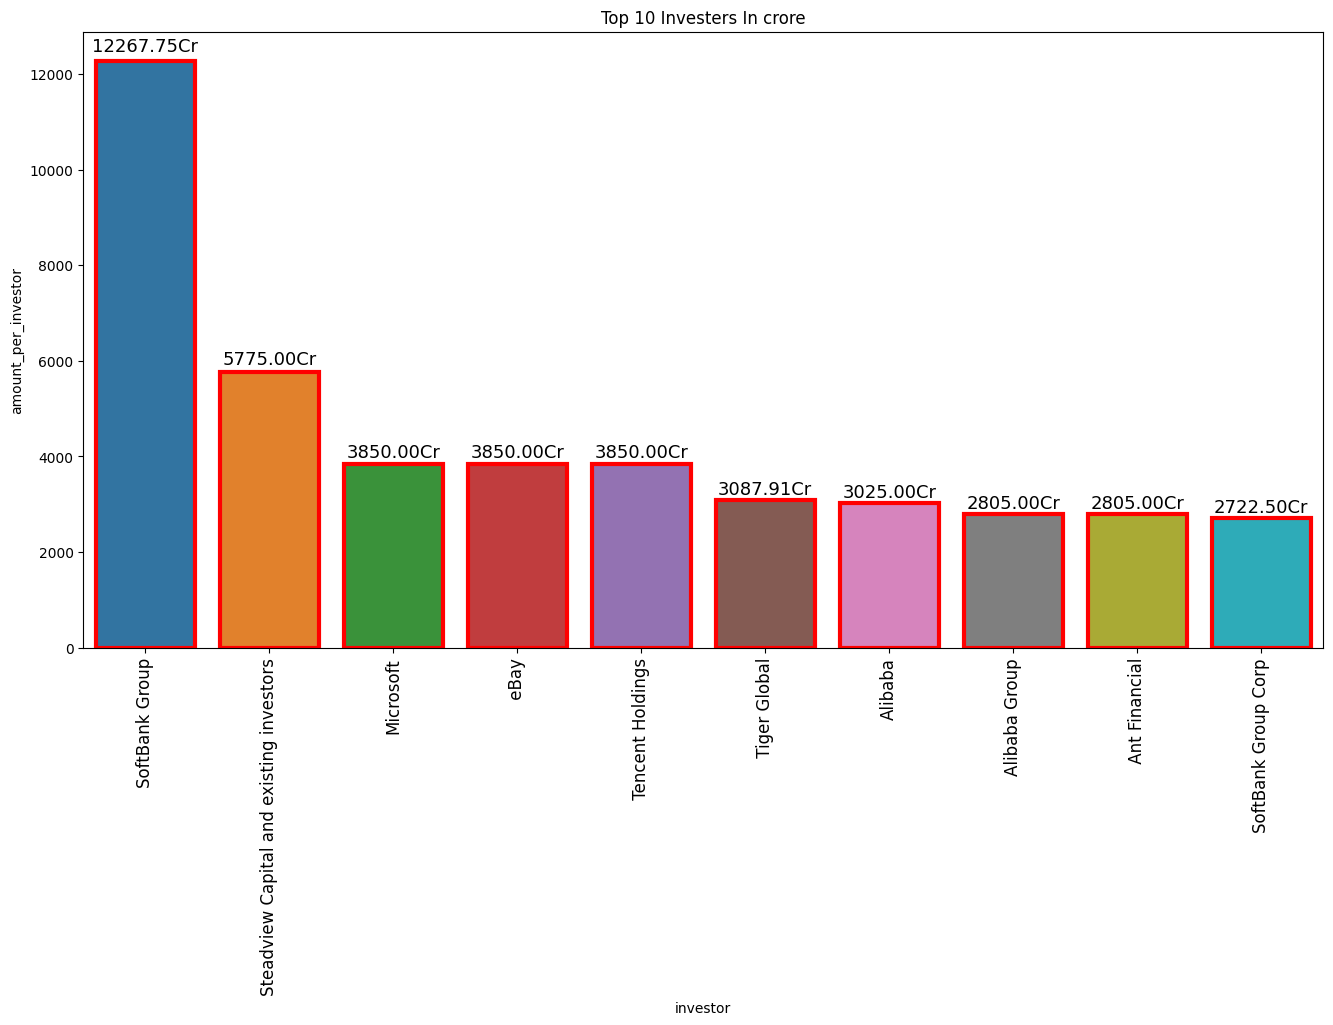

In [ ]:
plt.figure(figsize=(16,8))
plt.title("Top 10 Investers In crore")

ax=sns.barplot(data=top_10_inverstors,edgecolor='red',linewidth=3,x='investor',y='amount_per_investor',hue='investor')

plt.xticks(rotation=90,fontsize=12)
for i in ax.patches:
    height=i.get_height()
    ax.text(
        i.get_x() + i.get_width()/2 ,
        height + 0.01*height,
        f'{height:.2f}Cr',
        fontsize=13,
        color='black',
        ha='center',
        va='bottom'
    )

**💡 Insight — Top investors by equal-split capital:** when a round's amount is divided equally among co-investors, **SoftBank Group (₹12,268 Cr)** leads by a wide margin, followed by **Steadview Capital (₹5,775 Cr)** and a cluster of global names (Microsoft, eBay, Tencent) tied to a single large multi-investor round. This method is a simplification — real cap tables are rarely split equally — but it's a standard way to approximate each investor's "share of activity" when exact stakes aren't disclosed.

In [ ]:
# least 10 Investors
least_10=pd.DataFrame(requirement[requirement>0]).sort_values(by="amount_per_investor")
least_10

,amount_per_investor
investor,
Arihant Patni,0.0825
Lalit Mangal,0.0825
Dr. Ritesh Malik,0.0825
Anisha Mittal,0.0825
Samir Bangara,0.0825
...,...
Microsoft,3850.0000
eBay,3850.0000
Tencent Holdings,3850.0000


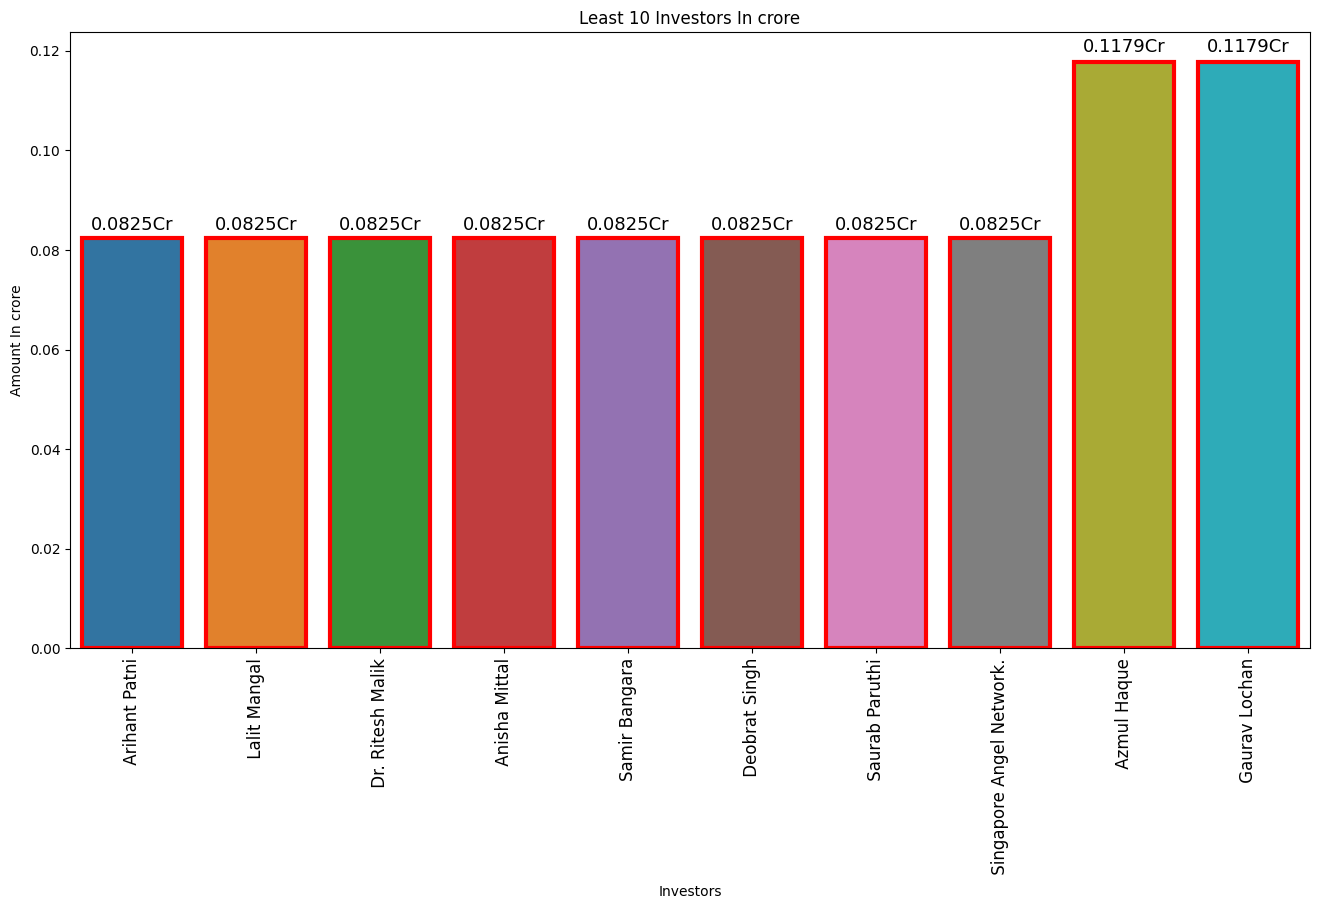

In [ ]:
plt.figure(figsize=(16,8))
plt.title("Least 10 Investors In crore")
plt.ylabel("Amount In crore")
plt.xlabel("Investors")
ax=sns.barplot(data=least_10.head(10),edgecolor='red',linewidth=3,x='investor',y='amount_per_investor',hue='investor')

plt.xticks(rotation=90,fontsize=12)
for i in ax.patches:
    height=i.get_height()

    ax.text(
        i.get_x() + i.get_width()/2 ,
        height + 0.01*height,
        f'{height:.4f}Cr',
        fontsize=13,
        color='black',
        ha='center',
        va='bottom'
   )



**💡 Insight — The long tail of investors:** at the other extreme, many investors' equal-split contribution is a tiny fraction of a crore (e.g. ₹0.08 Cr) — reflecting large syndicates where a round is split across many small angel investors.

## Single Investor Analysis

**Case study: IDG Ventures**

In [ ]:
# first Make List of all the Investors
# then convert it to Set for (removing Duplicates)
# then sort it using sorted() method
# way to get the Unique (Investor list) from column (that have ELements in form of list)
x=sorted(set(df['investor'].str.split(",").sum()))


In [ ]:
x[0:10]

['',
 ' & Others',
 ' 122 West Ventures',
 ' 1Crowd',
 ' 3ONE4 Capital Advisors',
 ' 3one4 Capital',
 ' 3one4 Capital Advisors LLP',
 ' 500 Start-Ups',
 ' 500 Startups',
 ' 500 Startups & Other HNIs']

In [ ]:
len(x)
# TOtal number of Unique Investors

2703

In [ ]:
# As we can see above method provide us the unique investors but there may be some errors because (S johr) and (s johr) both are same so we haev to use such lower and strip functions to remove reveal those patterns

len(sorted(set(df['investor'].str.split(",").apply(lambda x: [i.strip().lower() for i in x if i!=''] ).sum())))

2364

In [ ]:
# Lets find for specific investor from above list
# use .contains() to find the rows Which have That Investor Name
Investor_found=df[df['investor'].str.contains(" IDG Ventures")].loc[:,['Date','startup',"city",'investor','amount']]
Investor_found

,Date,startup,city,investor,amount
SNo,,,,,
291,2017-03-16,POPxo,New Delhi,"GREE Ventures, Kalaari Capital and IDG Venture...",25.575
339,2017-02-13,Sigtuple,Bangalore,"Accel Partners, IDG Ventures, Endiya Partners,...",47.850
538,2016-11-14,Active.ai,Singapore,"Kalaari Capital, IDG Ventures India",24.750
542,2016-11-15,PlaySimple,Bangalore,"SAIF Partners, IDG Ventures India",33.000
722,2016-09-23,CloudCherry,Chennai,"Vertex Ventures, Cisco Ventures, IDG Ventures",49.500
833,2016-07-04,Curefit,Bangalore,"Accel Partners, IDG Ventures, Kalaari Capital",123.750
863,2016-07-13,RentMojo,Bangalore,"Accel Partners, IDG Ventures India",41.250
1000,2016-05-04,Lenskart,New Delhi,"International Finance Corp, TPG Growth, Adveq ...",495.000
1260,2016-02-08,Xpressbees,Pune,"SAIF Partners, IDG Ventures India, Vertex Vent...",103.125


In [ ]:
# grouping the startup column with amount because the single Investor may invest in same Company(startup) again
# then sum the amount according to the startups name
Investor_found.groupby('startup')['amount'].sum().sort_values(ascending=False)

,amount
startup,
Lenskart,495.000
Curefit,123.750
Xpressbees,103.125
FirstCry.com,82.500
CloudCherry,49.500
Sigtuple,47.850
RentMojo,41.250
Aasaanjobs,41.250
PlaySimple,33.000


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Lenskart'),
  Text(1, 0, 'Curefit'),
  Text(2, 0, 'Xpressbees'),
  Text(3, 0, 'FirstCry.com'),
  Text(4, 0, 'CloudCherry'),
  Text(5, 0, 'Sigtuple'),
  Text(6, 0, 'RentMojo'),
  Text(7, 0, 'Aasaanjobs'),
  Text(8, 0, 'PlaySimple'),
  Text(9, 0, 'POPxo')])

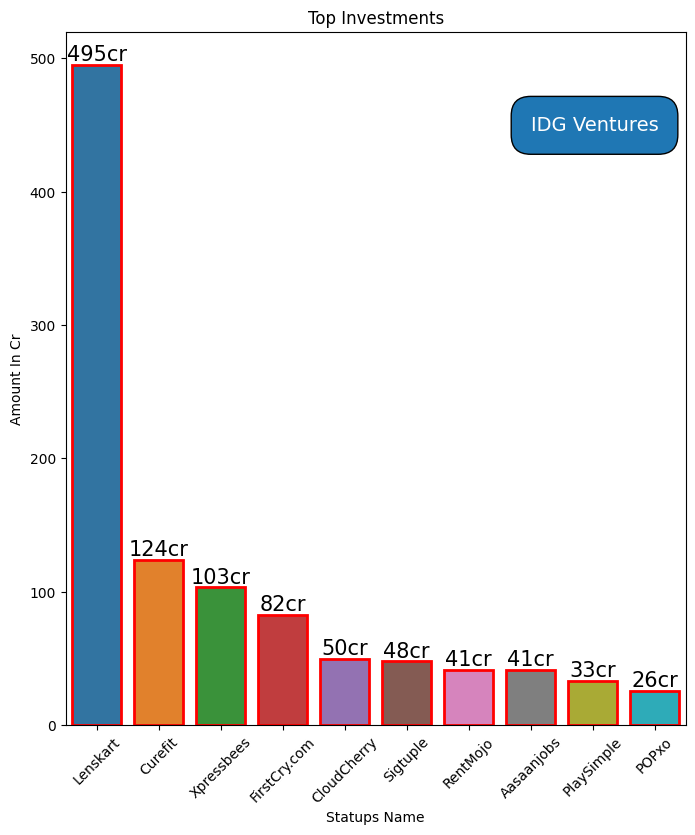

In [ ]:
# plotting top 10 investments by  IDG Ventures in startups
fig=plt.figure(figsize=(8,9))
import seaborn as sns
req=df[df['investor'].str.contains(" IDG Ventures")].groupby('startup')['amount'].sum().sort_values(ascending=False).head(10).reset_index()
ax=sns.barplot(data=req,x='startup',y='amount',hue='startup',linewidth=2,edgecolor='red')

ax.set_title("Top Investments")
ax.set_ylabel("Amount In Cr")
ax.set_xlabel("Statups Name")
for i in ax.patches:
    height=i.get_height()
    ax.text(
        i.get_x()+i.get_width()/2,
        height,
        f'{height:.0f}cr',
        va='bottom',ha='center',
        fontsize=15
    )
ax.text(
    7,                        # x-coordinate (slightly outside the bar)
    max(req['amount']) * 0.9,         # y-coordinate (90% of max height)
    "IDG Ventures",             # Your custom label
    fontsize=14,
    color='white',
    bbox=dict( edgecolor='black', boxstyle='round,pad=1.0')
)

plt.xticks(rotation=45)

**💡 Insight — IDG Ventures' biggest bets:** among startups IDG Ventures invested in, **Lenskart (₹495 Cr)** stands out well above the rest (Curefit ₹124 Cr, Xpressbees ₹103 Cr) — suggesting Lenskart was a flagship, high-conviction bet rather than one of many similarly sized investments.

vertical
Consumer Internet                  4
Technology                         4
eCommerce                          2
ECommerce                          1
global community for travellers    1
CRM / Analytics platform           1
Name: count, dtype: int64


<Axes: ylabel='count'>

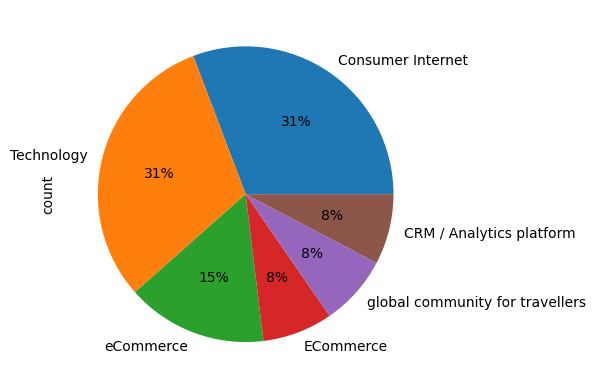

In [ ]:
# To get the In which sector the Invester Invests (Its interest )
# How many times investor invest in particular sector
print(df[df['investor'].str.contains(" IDG Ventures")]['vertical'].value_counts())
df[df['investor'].str.contains(" IDG Ventures")]['vertical'].value_counts().plot(kind='pie', autopct=lambda p: '{:.0f}%'.format(p))


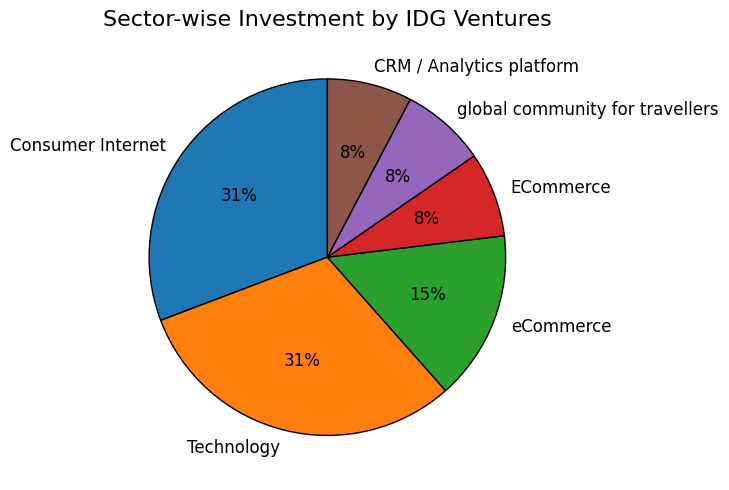

In [ ]:
# more Better Vesion of Above
plt.figure(figsize=(8, 5))  # Increase the figure size
plt.title("Sector-wise Investment by IDG Ventures", fontsize=16)  # Add a title with larger font size

# Plot the pie chart with better spacing and larger font sizes
df[df['investor'].str.contains(" IDG Ventures")]['vertical'].value_counts().plot(
    kind='pie',
    autopct=lambda p: '{:.0f}%'.format(p),
    textprops={'fontsize': 12},
    startangle=90,
    wedgeprops={'linewidth': 1, 'edgecolor': 'black'}
)

plt.ylabel('')  # Remove the default y-axis label
plt.tight_layout()
plt.show()

                                  amount
vertical                                
CRM / Analytics platform           8.250
Consumer Internet                231.825
ECommerce                        103.125
Technology                       155.100
eCommerce                        577.500
global community for travellers    0.000


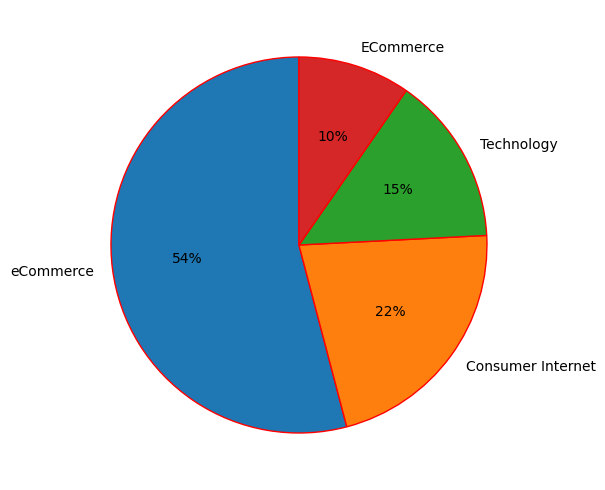

In [ ]:
# similarly how much investor INvest in specific Sector
print(df[df['investor'].str.contains(" IDG Ventures")].groupby("vertical")['amount'].sum().to_frame())

fig=plt.figure(figsize=(8,5))
df[df['investor'].str.contains(" IDG Ventures")].groupby("vertical")['amount'].sum().sort_values(ascending=False).head(4).plot(kind='pie',autopct=lambda p:'{:.0f}%'.format(p),startangle=90,
                                                                                          wedgeprops={'linewidth':1,'edgecolor':'red'})
plt.ylabel("")
plt.tight_layout()
plt.show()

**💡 Insight — IDG Ventures' sector focus:** the pie/bar breakdown shows IDG Ventures spread bets across **Consumer Internet, Technology, and eCommerce** fairly evenly by deal count, but capital was concentrated in **eCommerce (₹577.5 Cr)** — again driven by the Lenskart position.

/tmp/ipykernel_1267/4662483.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df[df['investor'].str.contains(" IDG Ventures")].groupby('round')['amount'].sum().sort_values(ascending=False).head(4).plot(kind='pie',autopct=lambda p:'{:.0f}%'.format(p) if p>0 else '')


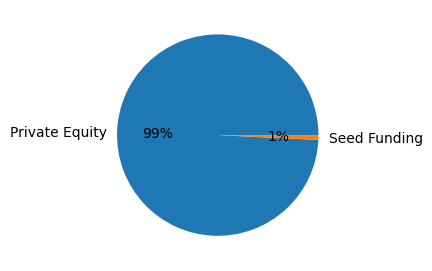

In [ ]:
# for Investor Round
fig=plt.figure(figsize=(4,3.5))
df[df['investor'].str.contains(" IDG Ventures")].groupby('round')['amount'].sum().sort_values(ascending=False).head(4).plot(kind='pie',autopct=lambda p:'{:.0f}%'.format(p) if p>0 else '')
plt.ylabel("")
plt.tight_layout()
plt.show()

<Axes: xlabel='Year', ylabel='amount'>

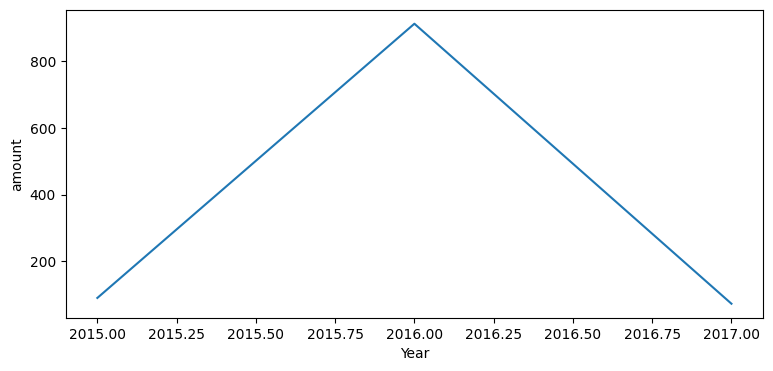

In [ ]:
# Year wise analysis about particular Investor
date_wise_investor=df[df['investor'].str.contains(" IDG Ventures")].sort_values(by='Date')
date_wise_investor['Year']=date_wise_investor['Date'].dt.year
fg,ax=plt.subplots(figsize=(9,4))
sns.lineplot(data=date_wise_investor.groupby("Year")['amount'].sum())
# date_wise_investor.groupby('Year')['amount'].sum().plot()

**💡 Insight — IDG Ventures' activity over time:** the year-wise trend shows IDG Ventures' capital deployment was concentrated in specific years rather than spread evenly — typical of a fund making a small number of large commitments rather than many similarly sized annual investments.

# __Overall Analysis__

1. __Total Amount Funded in our India Startups System__

In [ ]:
df['amount'].sum()

np.float64(140812.671516)

**💡 Insight — Total capital tracked:** the dataset captures **₹1,40,812.67 Cr (~₹1.4 lakh Cr)** of disclosed startup funding across 2015–2017. Remember: this excludes the 798 records with undisclosed amounts (Q13), so real total capital raised was almost certainly higher.

2. __Month wise analysis of amount funded in startups per Year__

In [ ]:
month_analysis=df.copy()
month_analysis['month']=month_analysis['Date'].dt.month
month_analysis['year']=month_analysis['Date'].dt.year
month_analysis.groupby(['year','month'])['amount'].sum()

year  month
2015  4         8080.875000
      5         2641.113750
      6         4302.325500
      7        13048.670250
      8         8776.482000
      9        12123.540000
      10        2103.428250
      11        7399.878750
      12        2523.287250
2016  1         5774.010000
      2         2734.796625
      3         2553.883266
      4         2095.005000
      5         2803.680000
      6         1647.021750
      7         1926.762750
      8         4406.234250
      9         1991.228250
      10        1958.946000
      11        2144.975250
      12        1544.754750
2017  1         2089.176375
      2         2433.411750
      3        18680.318250
      4         6042.258750
      5        14738.369250
      6         2842.818000
      7         1383.558000
      8           21.862500
Name: amount, dtype: float64

<Axes: xlabel='year,month'>

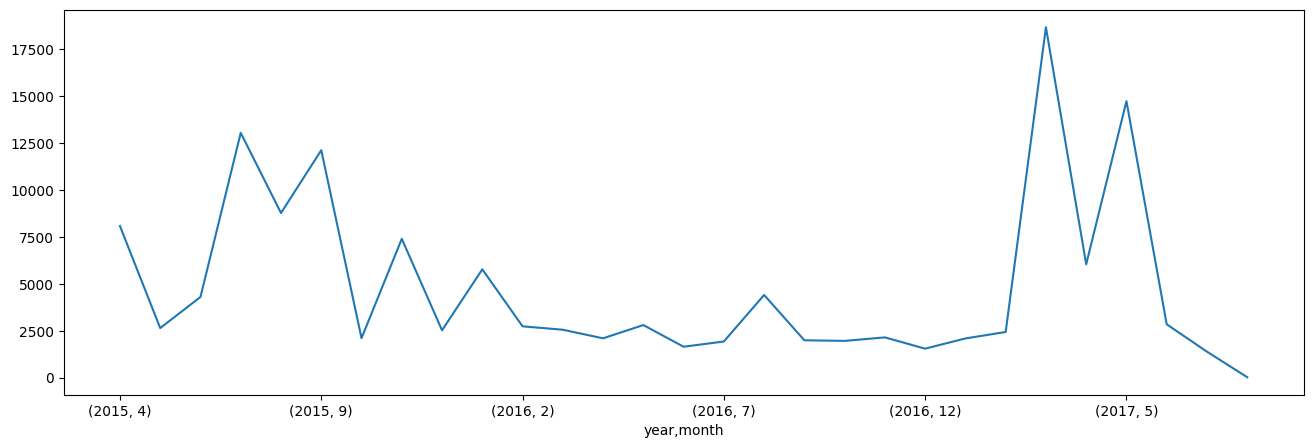

In [ ]:
plt.subplots(figsize=(16,5))
month_analysis.groupby(['year','month'])['amount'].sum().plot()

**💡 Insight:** Month-by-month total capital is far spikier than the *count* of deals (see Q7) — a handful of mega-rounds in specific months (e.g. mid-2015) dominate the total, even when the number of deals that month was unremarkable. This is the capital-concentration effect from Q2 showing up over time.

4. __Month wise analysis of how many times funded in startups per year__

In [ ]:
month_analysis.groupby(['year','month'])['startup'].count()

year  month
2015  4         61
      5         55
      6         84
      7         97
      8         98
      9         87
      10        93
      11        90
      12        88
2016  1        104
      2         99
      3         84
      4         77
      5         79
      6         97
      7         63
      8         87
      9         73
      10        80
      11        72
      12        72
2017  1         72
      2         48
      3         71
      4         71
      5         67
      6         65
      7         42
      8          5
Name: startup, dtype: int64

In [ ]:
df[(df['Date'].dt.year==2015) & (df['Date'].dt.month==4)].shape

(61, 12)

<Axes: xlabel='year,month'>

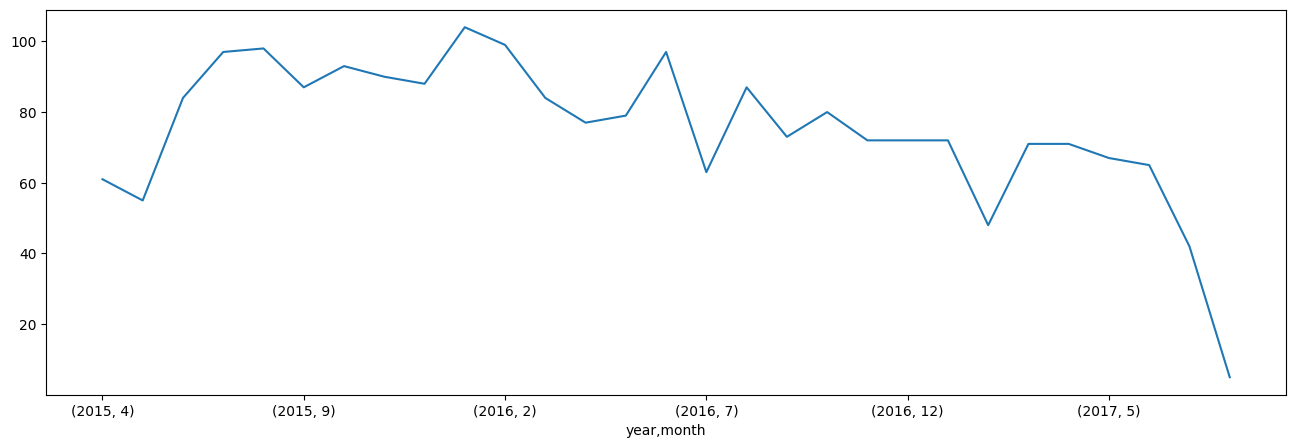

In [ ]:
plt.subplots(figsize=(16,5))
month_analysis.groupby(['year','month'])['startup'].count().plot()

**💡 Insight:** Unlike the amount trend, the *count* of funding events per month is much smoother — reinforcing that deal *volume* stayed fairly consistent while deal *value* was driven by a small number of outsized rounds.

# __Analysis About Startups__

__Top 10 startups invested__

In [ ]:
# applying strip and title functionto startup column
df['startup']=df['startup'].apply(lambda x: x.strip().title())

In [ ]:
# we have Done it above
df.groupby("startup")['amount'].sum().sort_values(ascending=False)

,amount
startup,
Paytm,17655.000
Flipkart,12867.525
Ola,8122.125
Flipkart.Com,5775.000
Snapdeal,5775.000
...,...
Cult Fitness,0.000
Shabdnagari,0.000
Shaadisaga,0.000


In [ ]:
# similarly for lower 10
# we have Done it above
df[df['amount']!=0].groupby("startup")['amount'].sum().sort_values(ascending=True)

,amount
startup,
Maptags,0.148500
33Coupons,0.165000
Soundsurround,0.185625
Strike,0.185625
Gamooz,0.185625
...,...
Snapdeal,5775.000000
Flipkart.Com,5775.000000
Ola,8122.125000


**💡 Insight:** At the bottom end, dozens of startups raised well under ₹1 Cr (e.g. Maptags at ₹0.15 Cr) — a reminder that this dataset spans everything from small angel cheques to billion-dollar-plus mega-rounds.

## Startup-Specific Analysis

**Case study: Lenskart**

__Highest Invested Amount In Lenskart Startup__

In [ ]:
particular_startup=df[df['amount']!=0][df['startup']=='Lenskart']
particular_startup

/tmp/ipykernel_1267/1635255404.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  particular_startup=df[df['amount']!=0][df['startup']=='Lenskart']


,Date,startup,vertical,subvertical,city,investor,round,amount,Year,month,startupcleaned,cleaned_investor
SNo,,,,,,,,,,,,
386,2017-01-10,Lenskart,eCommerce,Online eyewear retailer,Bangalore,Ronnie Screwvala,Private Equity,28.875,2017,1,lenskart,[ronnie screwvala]
1000,2016-05-04,Lenskart,eCommerce,Eyewear & Accessories etailer,New Delhi,"International Finance Corp, TPG Growth, Adveq ...",Private Equity,495.000,2016,5,lenskart,"[international finance corp, tpg growth, adveq..."


In [ ]:
# maximum Amount Funded To Lenskart
particular_startup[particular_startup['amount']==particular_startup['amount'].max()]

,Date,startup,vertical,subvertical,city,investor,round,amount,Year,month,startupcleaned,cleaned_investor
SNo,,,,,,,,,,,,
1000,2016-05-04,Lenskart,eCommerce,Eyewear & Accessories etailer,New Delhi,"International Finance Corp, TPG Growth, Adveq ...",Private Equity,495.0,2016,5,lenskart,"[international finance corp, tpg growth, adveq..."


**💡 Case Study — Lenskart's largest round:** Lenskart's biggest single disclosed round was **₹495 Cr (2016)**, funded by a syndicate including **IDG Ventures, Ratan Tata, Kris Gopalakrishnan, IFC, and Adveq Management**, among others — a strong signal of both institutional and high-profile angel confidence in the company.

__Max Amount Invested In Startup__

In [ ]:
particular_startup['amount'].max()

495.0

In [ ]:
# Which INvestors Funded To This Startup
particular_startup.explode('cleaned_investor')

,Date,startup,vertical,subvertical,city,investor,round,amount,Year,month,startupcleaned,cleaned_investor
SNo,,,,,,,,,,,,
386,2017-01-10,Lenskart,eCommerce,Online eyewear retailer,Bangalore,Ronnie Screwvala,Private Equity,28.875,2017,1,lenskart,ronnie screwvala
1000,2016-05-04,Lenskart,eCommerce,Eyewear & Accessories etailer,New Delhi,"International Finance Corp, TPG Growth, Adveq ...",Private Equity,495.000,2016,5,lenskart,international finance corp
1000,2016-05-04,Lenskart,eCommerce,Eyewear & Accessories etailer,New Delhi,"International Finance Corp, TPG Growth, Adveq ...",Private Equity,495.000,2016,5,lenskart,tpg growth
1000,2016-05-04,Lenskart,eCommerce,Eyewear & Accessories etailer,New Delhi,"International Finance Corp, TPG Growth, Adveq ...",Private Equity,495.000,2016,5,lenskart,adveq management
1000,2016-05-04,Lenskart,eCommerce,Eyewear & Accessories etailer,New Delhi,"International Finance Corp, TPG Growth, Adveq ...",Private Equity,495.000,2016,5,lenskart,idg ventures
1000,2016-05-04,Lenskart,eCommerce,Eyewear & Accessories etailer,New Delhi,"International Finance Corp, TPG Growth, Adveq ...",Private Equity,495.000,2016,5,lenskart,ratan tata
1000,2016-05-04,Lenskart,eCommerce,Eyewear & Accessories etailer,New Delhi,"International Finance Corp, TPG Growth, Adveq ...",Private Equity,495.000,2016,5,lenskart,kris gopalakrishnan


**Top investors in this startup, split equally by investor count**

If a round lists 5 investors and the total raised was ₹500 Cr, each investor's equal share is ₹500 Cr ÷ 5 = ₹100 Cr.

In [ ]:
particular_startup['Investor_no']=particular_startup['investor'].str.split(",").apply(len)
particular_startup['Amount_per_investor']=particular_startup['amount']/particular_startup['Investor_no']
particular_startup=particular_startup.explode("cleaned_investor").sort_values(by='Amount_per_investor',ascending=False)

In [ ]:
particular_startup

,Date,startup,vertical,subvertical,city,investor,round,amount,Year,month,startupcleaned,cleaned_investor,Investor_no,Amount_per_investor
SNo,,,,,,,,,,,,,,
1000,2016-05-04,Lenskart,eCommerce,Eyewear & Accessories etailer,New Delhi,"International Finance Corp, TPG Growth, Adveq ...",Private Equity,495.000,2016,5,lenskart,international finance corp,6,82.500
1000,2016-05-04,Lenskart,eCommerce,Eyewear & Accessories etailer,New Delhi,"International Finance Corp, TPG Growth, Adveq ...",Private Equity,495.000,2016,5,lenskart,tpg growth,6,82.500
1000,2016-05-04,Lenskart,eCommerce,Eyewear & Accessories etailer,New Delhi,"International Finance Corp, TPG Growth, Adveq ...",Private Equity,495.000,2016,5,lenskart,adveq management,6,82.500
1000,2016-05-04,Lenskart,eCommerce,Eyewear & Accessories etailer,New Delhi,"International Finance Corp, TPG Growth, Adveq ...",Private Equity,495.000,2016,5,lenskart,ratan tata,6,82.500
1000,2016-05-04,Lenskart,eCommerce,Eyewear & Accessories etailer,New Delhi,"International Finance Corp, TPG Growth, Adveq ...",Private Equity,495.000,2016,5,lenskart,idg ventures,6,82.500
1000,2016-05-04,Lenskart,eCommerce,Eyewear & Accessories etailer,New Delhi,"International Finance Corp, TPG Growth, Adveq ...",Private Equity,495.000,2016,5,lenskart,kris gopalakrishnan,6,82.500
386,2017-01-10,Lenskart,eCommerce,Online eyewear retailer,Bangalore,Ronnie Screwvala,Private Equity,28.875,2017,1,lenskart,ronnie screwvala,1,28.875


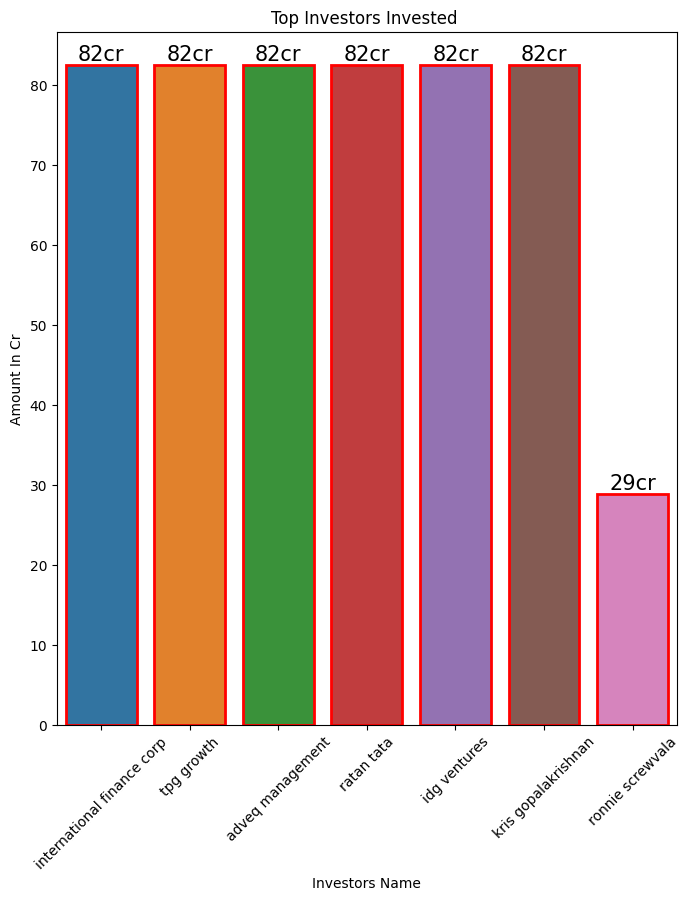

In [ ]:
# plotting top 10 investments by  IDG Ventures in startups
fig=plt.figure(figsize=(8,9))

ax=sns.barplot(data=particular_startup,x='cleaned_investor',y='Amount_per_investor',hue='cleaned_investor',linewidth=2,edgecolor='red')

ax.set_title("Top Investors Invested ")
ax.set_ylabel("Amount In Cr")
ax.set_xlabel("Investors Name")
for i in ax.patches:
    height=i.get_height()
    ax.text(
        i.get_x()+i.get_width()/2,
        height,
        f'{height:.0f}cr',
        va='bottom',ha='center',
        fontsize=15
    )

plt.xticks(rotation=45)
plt.show()

**💡 Insight:** Splitting Lenskart's ₹495 Cr round equally across its 6 listed investors highlights how syndicate-style deals dilute any single investor's *apparent* contribution — useful context when comparing "top investors" rankings across different deal structures.

In [ ]:
particular_startup.explode("cleaned_investor").groupby(['Date','startup','cleaned_investor'])['amount'].count()

Date        startup   cleaned_investor          
2016-05-04  Lenskart  adveq management              1
                      idg ventures                  1
                      international finance corp    1
                      kris gopalakrishnan           1
                      ratan tata                    1
                      tpg growth                    1
2017-01-10  Lenskart  ronnie screwvala              1
Name: amount, dtype: int64

In [ ]:
x=particular_startup.explode("cleaned_investor").groupby(['Date','startup','cleaned_investor'])['amount'].count().reset_index()

In [ ]:
# investor Numbers
x.loc[:,['Date','cleaned_investor']].groupby("Date").count()

,cleaned_investor
Date,
2016-05-04,6
2017-01-10,1


__Year Wise Analysis__

In [ ]:
particular_startup.groupby('Year')["amount"].sum()

,amount
Year,
2016,2970.000
2017,28.875


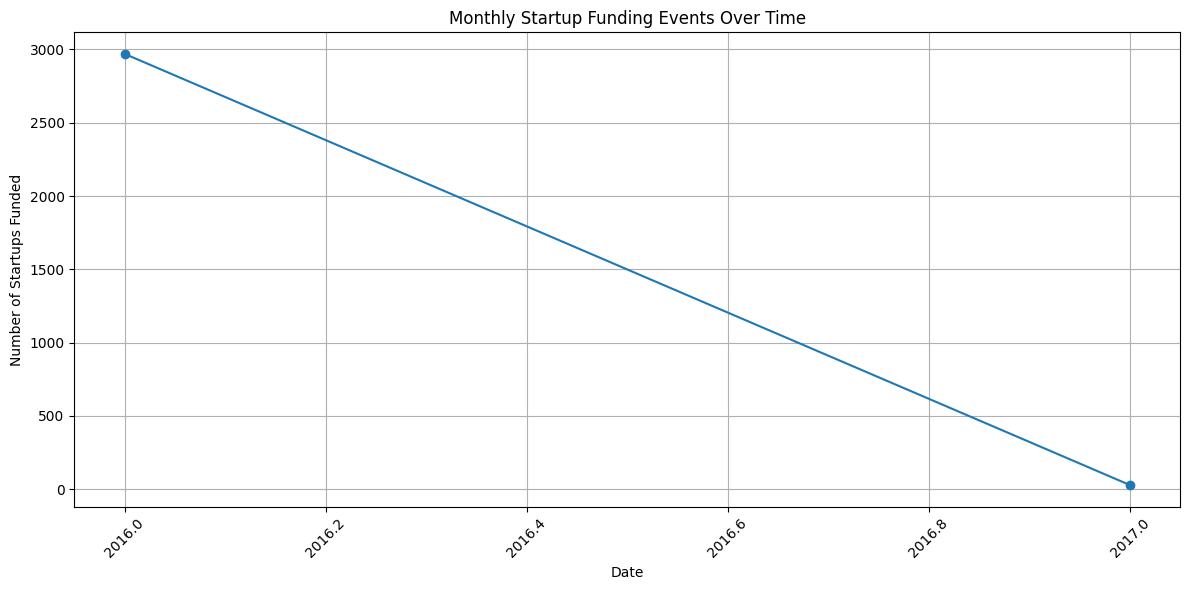

In [ ]:
year_wise=particular_startup.groupby('Year')["amount"].sum().reset_index(name='Total Amount In (Cr)')
plt.figure(figsize=(12, 6))
plt.plot(year_wise['Year'], year_wise['Total Amount In (Cr)'], marker='o')
plt.title('Monthly Startup Funding Events Over Time')
plt.xlabel('Date')
plt.ylabel('Number of Startups Funded')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

**💡 Insight — Lenskart's funding by year:** the bulk of Lenskart's disclosed capital (₹495 Cr) came in **2016**, with a much smaller follow-on amount (₹28.9 Cr) in 2017 — consistent with 2016 being the company's major growth-capital year.

__Most Invested Year__

In [ ]:
particular_startup.groupby('Year')["amount"].sum().reset_index(name='Total Amount In (Cr)').sort_values(by='Total Amount In (Cr)',ascending=False)['Year'][0]

np.int32(2016)

---

# 🏁 Key Insights & Conclusions

## 📊 Summary of Findings

1. **Funding is a power-law game.** A small number of mega-rounds (Paytm, Flipkart, Ola) dominate total capital, while the median deal (~₹2.5 Cr) is modest. Any "average" funding figure is misleading without also looking at the median and distribution shape.
2. **The ecosystem was metro-centric.** Bangalore, Mumbai, and New Delhi captured the overwhelming majority of both deal count and capital — tier-2/3 cities were largely absent from the venture funding map in 2015–2017.
3. **E-Commerce and Consumer Internet were the dominant sectors** by capital, consistent with the "internet economy" investment wave of that period.
4. **Seed-stage deals slightly outnumber growth-stage (PE) deals**, but growth-stage deals carry far more capital per round — early-stage activity is broad, late-stage capital is concentrated.
5. **2016 was the peak year** for funding events; 2017 data in this dataset is incomplete (partial year), so year-over-year comparisons involving 2017 should be read with that caveat.
6. **Data quality matters as much as analysis.** Startup names (`Flipkart` vs `Flipkart.Com`), city names (`Bangalore` vs `bangalore`), and vertical labels (`ECommerce` vs `eCommerce`) all had inconsistent entries — a reminder that a large share of "real-world" analysis time goes into cleaning, not modeling.
7. **~37% of records have undisclosed funding amounts.** Every total-capital figure in this notebook (₹1.4 lakh Cr) is a **lower bound**, not the true total raised.

## ❓ Questions This Analysis Raises (Ideas for Further Work)

Working through this dataset surfaced follow-up questions the current data can't fully answer, but would be worth exploring next:

- **Survivorship:** Which of these funded startups are still operating today, and does early funding amount actually predict long-term survival or a successful exit?
- **Investor specialization vs. spray-and-pray:** Do investors like Sequoia or Accel show a consistent sector focus over time, or do they diversify broadly across verticals?
- **City-level ROI:** Bangalore has the most startups and highest capital — but does it also have the highest *success rate* per startup funded, or just the highest volume?
- **The "undisclosed amount" bias:** Are undisclosed-amount deals systematically smaller/larger, earlier/later stage, or clustered in particular sectors? This would materially change the ₹1.4 lakh Cr total-capital estimate.
- **Round-to-round progression:** For the 241 startups funded multiple times, how much time typically passes between rounds, and does round size grow predictably (seed → Series A → PE) or erratically?
- **Sector timing:** Did later sectors (e.g. Fintech, HealthTech) start attracting capital as E-Commerce/Consumer Internet dominance faded post-2016? (Would require extending the dataset beyond 2017.)
- **Name/entity resolution at scale:** How much would total rankings shift with a rigorous fuzzy-matching pass on startup and investor names, instead of manual fixes like the `ECommerce`/`eCommerce` merge done here?
---
*Dataset: Indian Startup Funding (2015–2017) · Analysis by: Anushka Sahu · Tools: pandas, numpy, matplotlib, seaborn*
